In [1]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

In [2]:
# Load model
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1
)

# Load image
image = mp.Image.create_from_file("labeled_data/fane_data/angry/angry1.jpg")

# Detect landmarks
with FaceLandmarker.create_from_options(options) as landmarker:
    result = landmarker.detect(image)

I0000 00:00:1793773917.933810 12615088 init-domain.cc:133] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
W0000 00:00:1793773917.934245 12615088 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793773917.938470 12615092 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793773917.948623 12615092 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Number of landmarks: 478


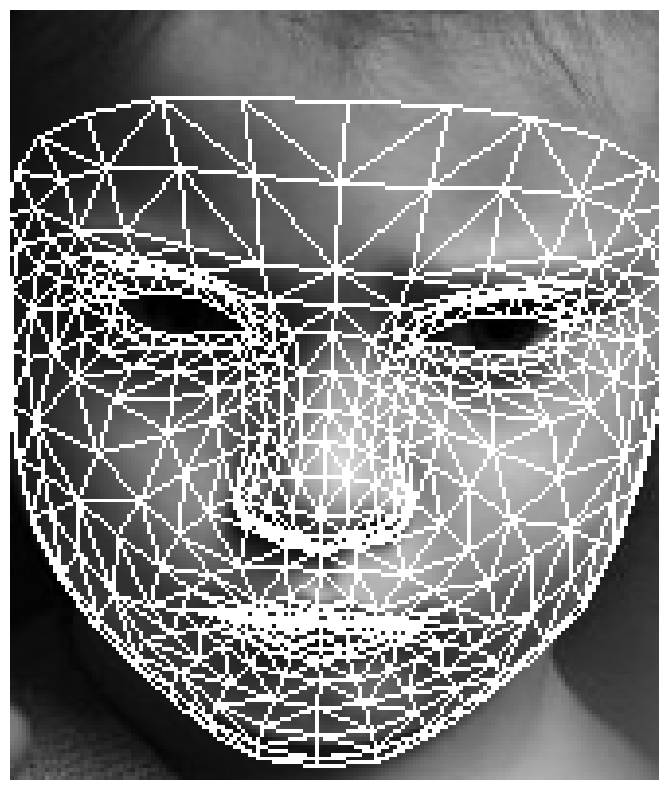

In [3]:
# Visualize
annotated_image = image.numpy_view().copy()
height, width, _ = annotated_image.shape

if result.face_landmarks:
    landmarks = result.face_landmarks[0]

    connections = (mp.tasks.vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION)

    for connection in connections:
        start = landmarks[connection.start]
        end = landmarks[connection.end]

        p1 = (int(start.x * width), int(start.y * height))
        p2 = (int(end.x * width), int(end.y * height))

        cv2.line(annotated_image, p1, p2, (0, 255, 0), 1)

    print(f"Number of landmarks: {len(landmarks)}")

plt.figure(figsize=(10, 10))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()

In [4]:
print(landmarks)
print(len(landmarks))

[NormalizedLandmark(x=0.4755217432975769, y=0.7753484845161438, z=-0.049635209143161774, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.4787318706512451, y=0.6852378845214844, z=-0.21425101161003113, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.4787788391113281, y=0.7032135725021362, z=-0.079135000705719, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.4497564435005188, y=0.5625569820404053, z=-0.21128509938716888, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.4806261658668518, y=0.6559385061264038, z=-0.24410049617290497, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.48379820585250854, y=0.6065197587013245, z=-0.24744662642478943, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.49486541748046875, y=0.47062361240386963, z=-0.19468165934085846, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.1753363013267517, y=0.3946229815483093, z=-0.032666247338

# Build a NN for the landmarks

In [5]:
import torch as th
import numpy as np


## Extract data

In [6]:
def extract_features(image):
    with FaceLandmarker.create_from_options(options) as landmarker:
        result = landmarker.detect(image)
    # landmarks = result.face_landmarks[0]
    if result.face_landmarks:
        landmarks = result.face_landmarks[0]

        connections = (mp.tasks.vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION)

        for connection in connections:
            start = landmarks[connection.start]
            end = landmarks[connection.end]

            p1 = (int(start.x * width), int(start.y * height))
            p2 = (int(end.x * width), int(end.y * height))
            
            cv2.line(annotated_image, p1, p2, (0, 255, 0), 1)
    print("hi")
    features = np.array([
        [lm.x, lm.y, lm.z]
        for lm in landmarks
    ], dtype=np.float32)

    return features
print(extract_features(image))

hi
[[ 0.47552174  0.7753485  -0.04963521]
 [ 0.47873187  0.6852379  -0.21425101]
 [ 0.47877884  0.7032136  -0.079135  ]
 ...
 [ 0.7574956   0.38207757 -0.04966702]
 [ 0.7043192   0.4136063  -0.0497165 ]
 [ 0.75414795  0.44955772 -0.04971055]]


W0000 00:00:1793773919.290130 12615120 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1793773919.294112 12615124 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793773919.303484 12615123 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [7]:
# Createa labels
neutral = np.zeros(10)
angry = np.ones(10)
confused = np.ones(10)*2
disgust = np.ones(10)*3
fear = np.ones(10)*4
happy = np.ones(10)*5
sad = np.ones(10)*6
shy = np.ones(10)*7
suprise = np.ones(10)*8

Y = np.concatenate((neutral, angry, confused, disgust, fear, happy, sad, shy, suprise), axis=0)
print(Y)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 4. 4. 4. 4. 4. 4. 4. 4.
 4. 4. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 7. 7.
 7. 7. 7. 7. 7. 7. 7. 7. 8. 8. 8. 8. 8. 8. 8. 8. 8. 8.]


In [8]:
import random
import shutil
from pathlib import Path

SRC = Path("labeled_data/fane_data")            # folder containing the emotion subfolders
DST = Path("sample_10")       # output folder
EMOTIONS = ["neutral", "angry", "confused", "disgust", "fear",
            "happy", "sad", "shy", "surprise"]  # check spelling vs. your folders ("suprise"?)
N = 10
random.seed(42)

for emotion in EMOTIONS:
    folder = SRC / emotion
    if not folder.exists():
        print(f"Missing folder: {folder}")
        continue

    images = [p for p in folder.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg"}]
    if len(images) < N:
        print(f"{emotion}: only {len(images)} images, taking all")
    # picked = random.sample(images, min(N, len(images)))
    X = np.zeros(9*N)
    for i in range(N):
        image = mp.Image.create_from_file(images[i])
        features = extract_features(image)
        X[i*9:(i+1)*9] = features.flatten()

    # out = DST / emotion
    # out.mkdir(parents=True, exist_ok=True)
    # for p in picked:
    #     shutil.copy(p, out / p.name)

    # print(f"{emotion}: copied {len(picked)} images")
    print(X)

AttributeError: 'PosixPath' object has no attribute 'encode'

In [18]:
import random
from pathlib import Path

import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

SRC = Path("labeled_data/fane_data")   # check this path ("face_data"?)
EMOTIONS = ["neutral", "angry", "confused", "disgust", "fear",
            "happy", "sad", "shy", "surprise"]   # check spelling vs. your folders ("suprise"?)
N = 650
random.seed(42)

# --- create the landmarker once ---
options = vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
)
landmarker = vision.FaceLandmarker.create_from_options(options)


def extract_features(image):
    """Return (478, 3) array of landmarks, or None if no face found."""
    result = landmarker.detect(image)
    if not result.face_landmarks:
        return None
    lms = result.face_landmarks[0]
    return np.array([[lm.x, lm.y, lm.z] for lm in lms], dtype=np.float32)


def normalize(landmarks):
    """Remove translation and scale (rotation alignment can be added later)."""
    pts = landmarks - landmarks.mean(axis=0)
    scale = np.linalg.norm(pts, axis=1).mean()
    return pts / scale


def draw_mesh(image_path, landmarks, out_path):
    """Optional: save an image with the tesselation drawn on it."""
    img = cv2.imread(str(image_path))
    h, w = img.shape[:2]
    conns = vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION
    for c in conns:
        a, b = landmarks[c.start], landmarks[c.end]
        cv2.line(img, (int(a.x * w), int(a.y * h)), (int(b.x * w), int(b.y * h)), (0, 255, 0), 1)
    cv2.imwrite(str(out_path), img)


X, y, paths = [], [], []

for emotion in EMOTIONS:
    folder = SRC / emotion
    if not folder.exists():
        print(f"Missing folder: {folder}")
        continue

    images = [p for p in folder.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg"}]
    picked = random.sample(images, min(N, len(images)))

    for p in picked:
        image = mp.Image.create_from_file(str(p))
        lms = extract_features(image)
        if lms is None:
            # print(f"No face detected: {p}")
            continue
        X.append(normalize(lms).flatten())   # 478*3 = 1434 values
        y.append(emotion)
        paths.append(str(p))

    print(f"{emotion}: {sum(1 for l in y if l == emotion)} usable images")

X = np.stack(X)
y = np.array(y)
print(X.shape, y.shape)   # e.g. (90, 1434) (90,)

W0000 00:00:1793781647.404622 12688156 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1793781647.412046 12688158 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793781647.440953 12688158 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


neutral: 618 usable images
angry: 591 usable images
confused: 622 usable images
disgust: 617 usable images
fear: 573 usable images
happy: 600 usable images
sad: 594 usable images
shy: 590 usable images
surprise: 615 usable images
(5420, 1434) (5420,)


In [19]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- data ----------
le = LabelEncoder()
y_int = le.fit_transform(y)                      # emotion names -> 0..8
X3 = X.reshape(len(X), 478, 3).astype(np.float32)

X_tr, X_va, y_tr, y_va = train_test_split(
    X3, y_int, test_size=0.2, stratify=y_int, random_state=42
)

class LandmarkDS(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = torch.tensor(X), torch.tensor(y), augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = self.X[i].clone()
        if self.augment:
            # small random in-plane rotation, scale, and jitter
            a = np.random.uniform(-0.15, 0.15)       # radians (~8 degrees)
            R = torch.tensor([[np.cos(a), -np.sin(a), 0],
                              [np.sin(a),  np.cos(a), 0],
                              [0, 0, 1]], dtype=torch.float32)
            x = x @ R.T
            x = x * np.random.uniform(0.95, 1.05)
            x = x + 0.003 * torch.randn_like(x)
        return x, self.y[i]

train_dl = DataLoader(LandmarkDS(X_tr, y_tr, augment=True), batch_size=32, shuffle=True)
val_dl   = DataLoader(LandmarkDS(X_va, y_va), batch_size=64)

n_classes = len(le.classes_)

# ---------- model 1: MLP baseline ----------
class NN(nn.Module):
    def __init__(self, n_classes, hidden=256, p=0.3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(478 * 3, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, 64), nn.ReLU(),
        )
        self.head = nn.Linear(64, n_classes)

    def embed(self, x):
        return self.encoder(x)

    def forward(self, x):
        return self.head(self.embed(x))

# ---------- model 2: landmark-as-token transformer ----------
class LandmarkTransformer(nn.Module):
    def __init__(self, n_classes, d=64, heads=4, layers=2, p=0.2):
        super().__init__()
        self.proj = nn.Linear(3, d)
        self.pos = nn.Parameter(torch.zeros(1, 478, d))   # learned position per landmark
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        nn.init.trunc_normal_(self.pos, std=0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=heads, dim_feedforward=4 * d,
            dropout=p, batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=layers)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_classes)

    def embed(self, x):                                   # x: (B, 478, 3)
        t = self.proj(x) + self.pos
        t = torch.cat([self.cls.expand(len(x), -1, -1), t], dim=1)
        return self.norm(self.encoder(t)[:, 0])           # CLS token

    def forward(self, x):
        return self.head(self.embed(x))

# ---------- training ----------
def run_epoch(model, dl, opt=None, loss_fn=None):
    train = opt is not None
    model.train(train)
    total, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            total += loss.item() * len(xb)
            preds += out.argmax(1).cpu().tolist()
            labels += yb.cpu().tolist()
    return total / len(dl.dataset), f1_score(labels, preds, average="macro"), preds, labels

def fit(model, epochs=150, lr=1e-3):
    model.to(device)
    counts = np.bincount(y_tr, minlength=n_classes)
    weights = torch.tensor(len(y_tr) / (n_classes * np.maximum(counts, 1)),
                           dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.1)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best_f1, best_state = 0, None
    for ep in range(epochs):
        tr_loss, tr_f1, _, _ = run_epoch(model, train_dl, opt, loss_fn)
        va_loss, va_f1, _, _ = run_epoch(model, val_dl, None, loss_fn)
        sched.step()
        if va_f1 > best_f1:
            best_f1, best_state = va_f1, {k: v.clone() for k, v in model.state_dict().items()}
        if ep % 10 == 0:
            print(f"ep {ep:3d} | train loss {tr_loss:.3f} f1 {tr_f1:.3f} | val loss {va_loss:.3f} f1 {va_f1:.3f}")
    model.load_state_dict(best_state)
    return model

for name, model in [("MLP", NN(n_classes))]:#, ("Transformer", LandmarkTransformer(n_classes))]:
    print(f"\n=== {name} ===")
    model = fit(model)
    _, f1, preds, labels = run_epoch(model, val_dl, None, nn.CrossEntropyLoss())
    print(f"best val macro-F1: {f1:.3f}")
    print(classification_report(labels, preds, target_names=le.classes_, zero_division=0))
    print(confusion_matrix(labels, preds))

# ---------- embeddings for clustering (later) ----------
@torch.no_grad()
def get_embeddings(model, X):
    model.eval().to(device)
    return model.embed(torch.tensor(X).to(device)).cpu().numpy()


=== MLP ===
ep   0 | train loss 2.075 f1 0.209 | val loss 2.008 f1 0.217
ep  10 | train loss 1.830 f1 0.339 | val loss 1.874 f1 0.317
ep  20 | train loss 1.786 f1 0.378 | val loss 1.828 f1 0.333
ep  30 | train loss 1.743 f1 0.383 | val loss 1.785 f1 0.372
ep  40 | train loss 1.713 f1 0.421 | val loss 1.834 f1 0.357
ep  50 | train loss 1.683 f1 0.429 | val loss 1.772 f1 0.378
ep  60 | train loss 1.645 f1 0.442 | val loss 1.773 f1 0.392
ep  70 | train loss 1.618 f1 0.463 | val loss 1.793 f1 0.371
ep  80 | train loss 1.586 f1 0.477 | val loss 1.767 f1 0.406
ep  90 | train loss 1.552 f1 0.498 | val loss 1.786 f1 0.399
ep 100 | train loss 1.536 f1 0.508 | val loss 1.784 f1 0.404
ep 110 | train loss 1.513 f1 0.526 | val loss 1.770 f1 0.410
ep 120 | train loss 1.486 f1 0.529 | val loss 1.760 f1 0.426
ep 130 | train loss 1.483 f1 0.538 | val loss 1.765 f1 0.418
ep 140 | train loss 1.472 f1 0.539 | val loss 1.764 f1 0.411
best val macro-F1: 0.426
              precision    recall  f1-score   s

In [20]:
idx = np.arange(len(X3))
idx_tr, idx_va = train_test_split(idx, test_size=0.2, stratify=y_int, random_state=42)

X_tr, X_va = X3[idx_tr], X3[idx_va]
y_tr, y_va = y_int[idx_tr], y_int[idx_va]
paths_va = [paths[i] for i in idx_va]     # image paths for the validation set

In [21]:
@torch.no_grad()
def predict(model, X):
    model.eval().to(device)
    logits = model(torch.tensor(X).to(device))
    probs = torch.softmax(logits, dim=1).cpu().numpy()
    return probs.argmax(1), probs

pred_va, probs_va = predict(model, X_va)

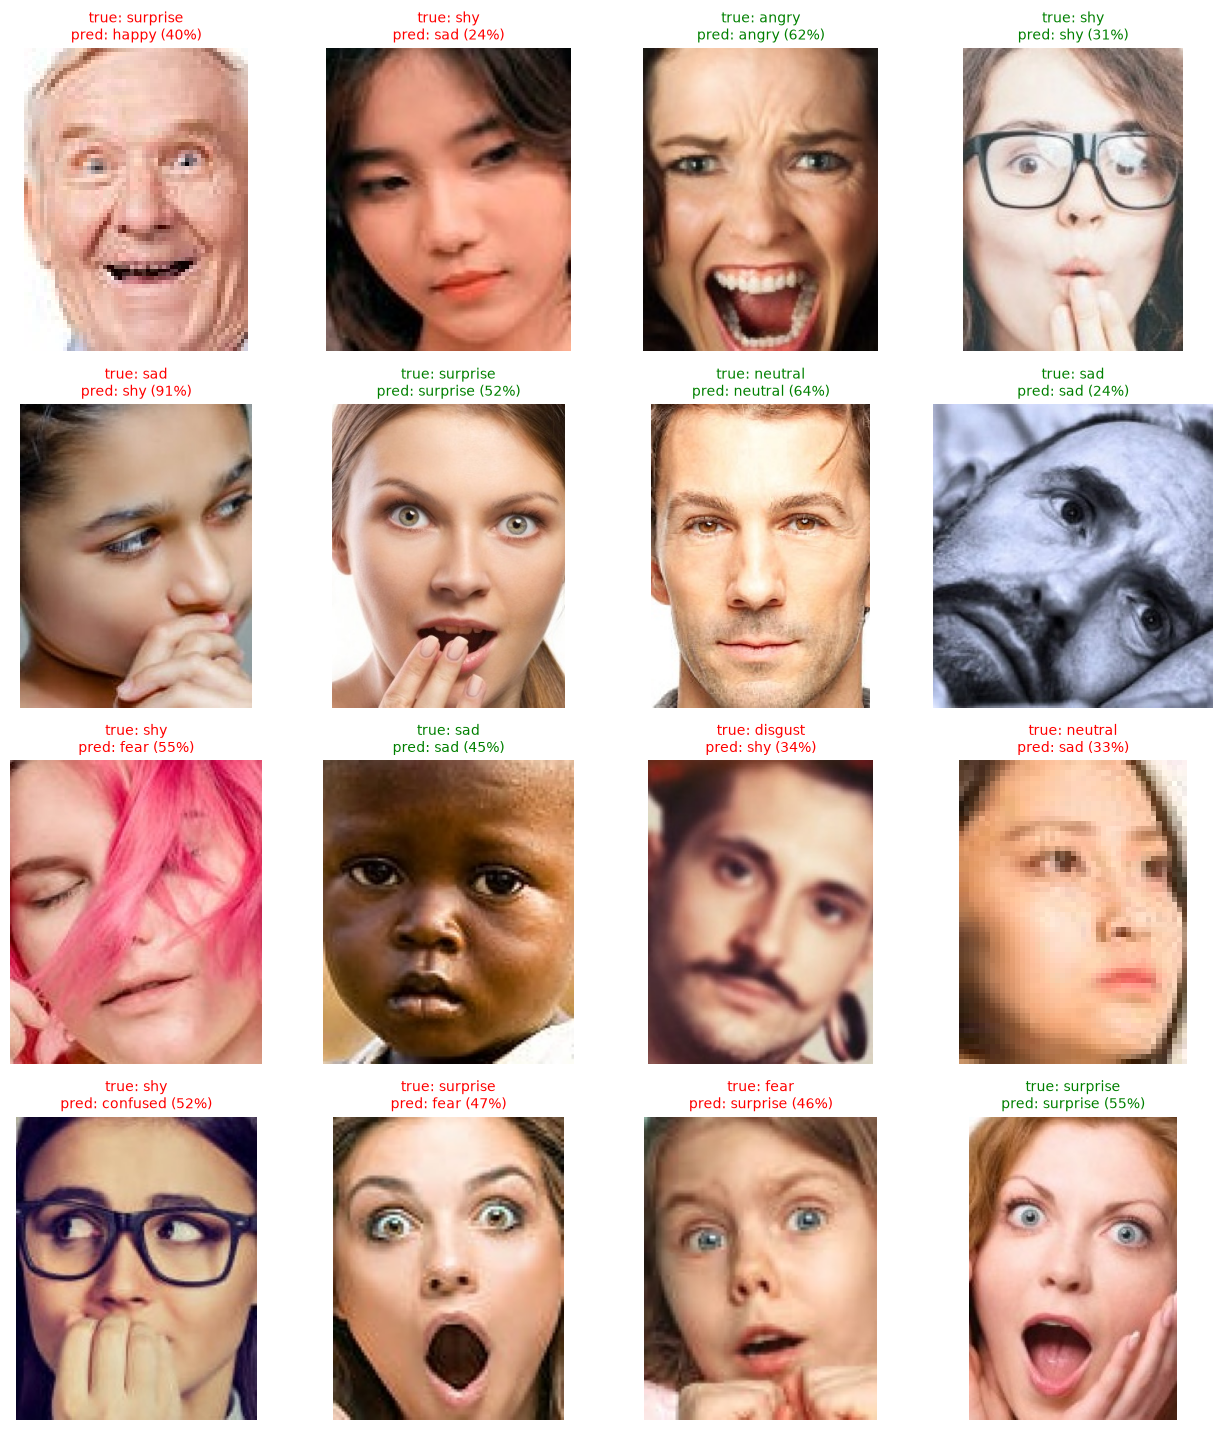

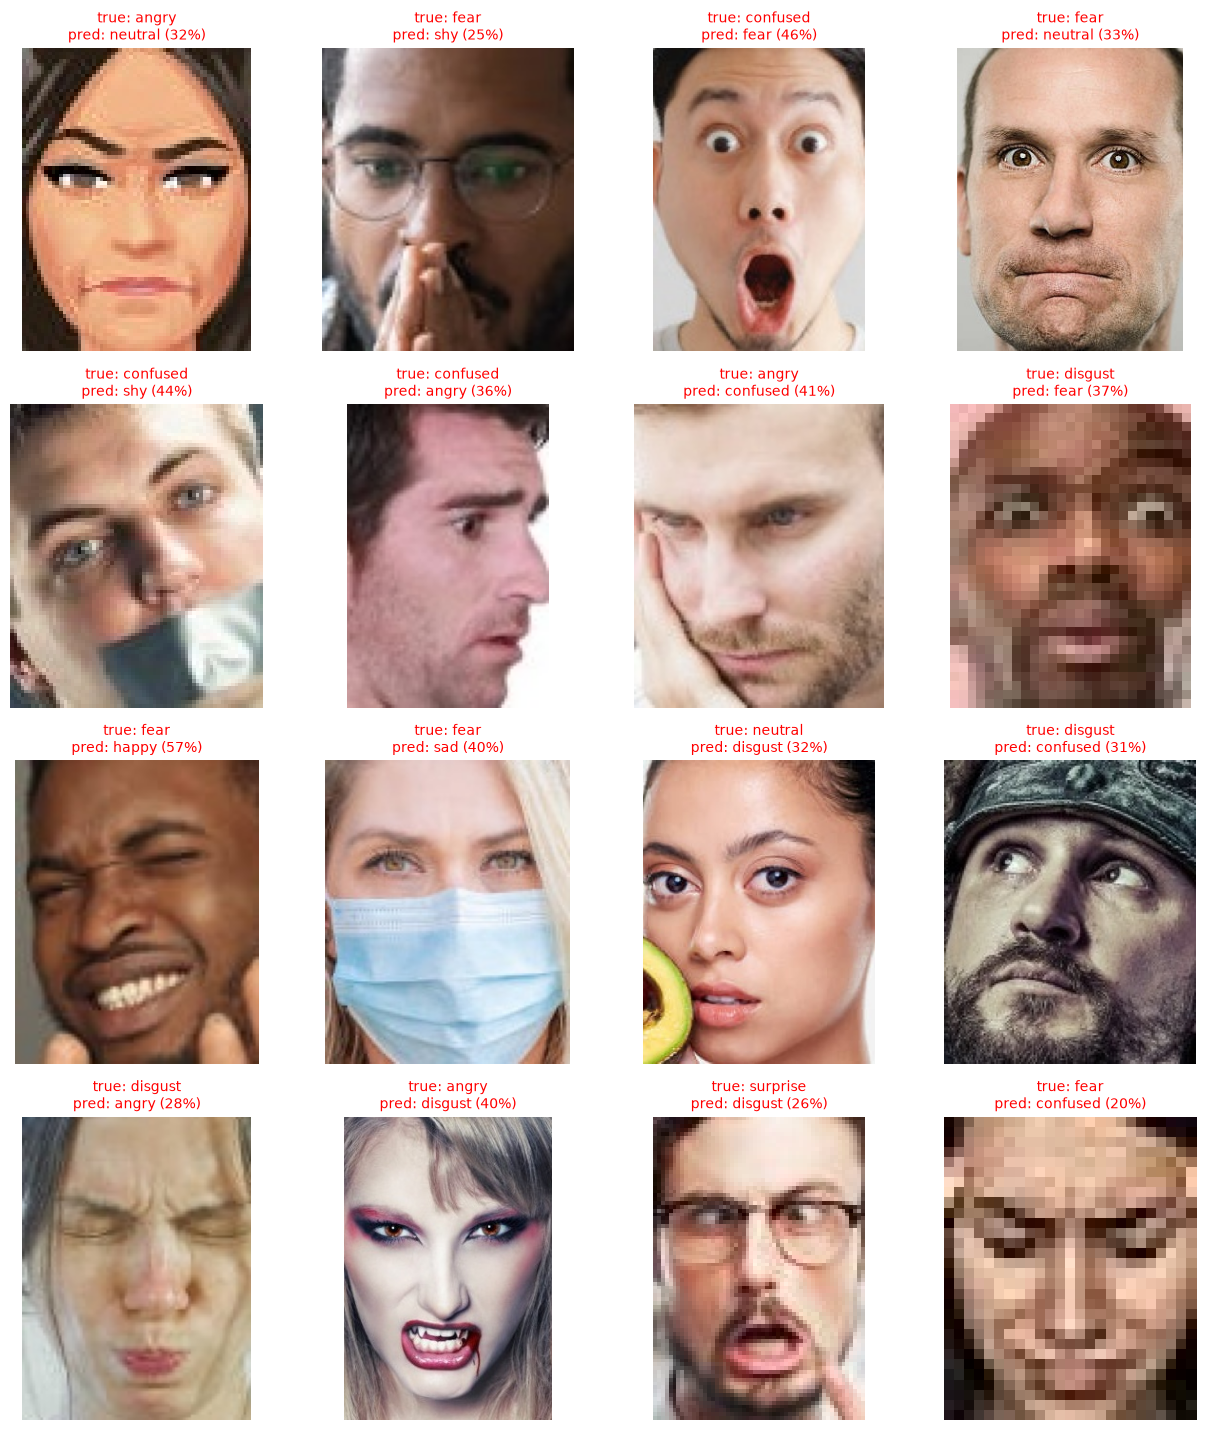

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

def show_predictions(paths, y_true, y_pred, probs, class_names,
                     only_wrong=False, n=16, cols=4, seed=0):
    ids = np.arange(len(paths))
    if only_wrong:
        ids = ids[y_true != y_pred]
    if len(ids) == 0:
        print("Nothing to show.")
        return
    rng = np.random.default_rng(seed)
    ids = rng.choice(ids, size=min(n, len(ids)), replace=False)

    rows = int(np.ceil(len(ids) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, i in zip(axes, ids):
        ax.imshow(Image.open(paths[i]))
        correct = y_true[i] == y_pred[i]
        ax.set_title(
            f"true: {class_names[y_true[i]]}\n"
            f"pred: {class_names[y_pred[i]]} ({probs[i].max():.0%})",
            color="green" if correct else "red", fontsize=10,
        )
        ax.axis("off")
    for ax in axes[len(ids):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# random sample of validation images
show_predictions(paths_va, y_va, pred_va, probs_va, le.classes_)

# only the mistakes
show_predictions(paths_va, y_va, pred_va, probs_va, le.classes_, only_wrong=True)